# Late Again: exploratory data analysis
### Toronto bus delays (TTC, 2023-2024) with weather and events

This notebook explores the real data behind the project, step by step. Run `python run_pipeline.py` first (or use the processed files already in the repo).

What one row means: The TTC publishes one row per *delay incident*: a breakdown, a diversion, a security call, an operator issue... `delay_min` is how late that incident made the next bus. So this is not a list of every trip: buses that ran on time do not appear.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

sys.path.append(str(Path.cwd().parent / "src"))
import analysis
from config import INCIDENTS_FILE, HOURLY_FILE, DAY_ORDER

sns.set_theme(style="whitegrid", font_scale=0.95)
inc = pd.read_csv(INCIDENTS_FILE, parse_dates=["timestamp"], dtype={"route": str})
hourly = pd.read_csv(HOURLY_FILE, parse_dates=["hour_ts"])
print(f"{len(inc):,} incidents, {len(hourly):,} hours, {inc['route'].nunique()} routes")
inc.head()

111,750 incidents, 17,544 hours, 310 routes


,timestamp,hour_ts,route,direction,location,at_station,incident,delay_min,gap_min,major_delay,...,humidity_pct,precipitation_mm,rain_mm,snowfall_cm,snow_depth_cm,wind_kmh,gust_kmh,weather_code,weather,jays_game_window
0,2023-01-01 01:13:00,2023-01-01 01:00:00,116,Unknown,KENNEDY STATION,1,Cleaning - Unsanitary,10,20,0,...,92,0.0,0.0,0.0,0.0,10.5,24.8,3,Cloudy,0
1,2023-01-01 01:27:00,2023-01-01 01:00:00,927,W,STEELES AND MARTIN GRO,0,Security,0,0,0,...,92,0.0,0.0,0.0,0.0,10.5,24.8,3,Cloudy,0
2,2023-01-01 01:54:00,2023-01-01 01:00:00,60,E,YONGE AND EMPRESS,0,Operations - Operator,7,14,0,...,92,0.0,0.0,0.0,0.0,10.5,24.8,3,Cloudy,0
3,2023-01-01 02:30:00,2023-01-01 02:00:00,91,Unknown,WOODBINE AND MORTIMER,0,Diversion,81,111,1,...,93,0.0,0.0,0.0,0.0,8.7,17.6,3,Cloudy,0
4,2023-01-01 02:34:00,2023-01-01 02:00:00,69,S,WARDEN STATION,1,Security,22,44,1,...,93,0.0,0.0,0.0,0.0,8.7,17.6,3,Cloudy,0


## 1. Data quality
`src/build_dataset.py` printed what it removed: rows with no readable time, exact duplicate reports, and delays over 120 minutes (mostly long diversions and typing errors, about 2% of rows). About 96.5% of the original incidents were kept. Every incident found a matching weather hour.

In [2]:
inc.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

## 2. How late is late?

count    111750.0
mean         14.8
std          13.6
min           0.0
25%           8.0
50%          11.0
75%          20.0
90%          27.0
max         120.0
Name: delay_min, dtype: float64
Major delays (15+ min): 38.7%


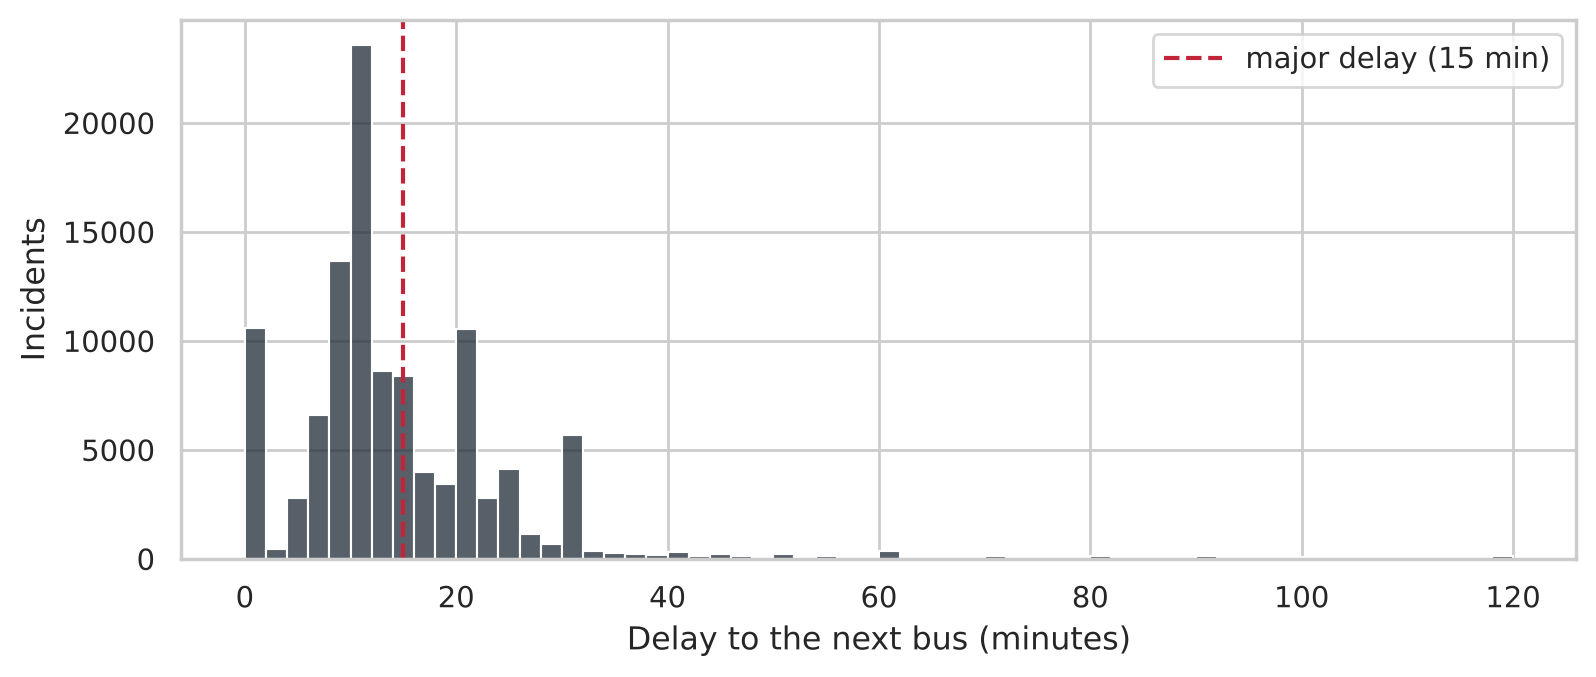

In [3]:
print(inc["delay_min"].describe(percentiles=[.25, .5, .75, .9]).round(1))
print(f"Major delays (15+ min): {inc['major_delay'].mean():.1%}")
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.histplot(inc["delay_min"], bins=60, color="#1F2A36", ax=ax)
ax.axvline(15, color="#C2253A", ls="--", label="major delay (15 min)"); ax.legend()
ax.set(xlabel="Delay to the next bus (minutes)", ylabel="Incidents");

Delays are skewed: half are 11 minutes or less, a few are very long. Spikes at round numbers (10, 20, 30 min) show that delays are often reported rounded. This is why the delay model is trained to minimise absolute error (it predicts a typical value, not an average pulled up by rare extremes).

## 3. When do incidents happen?

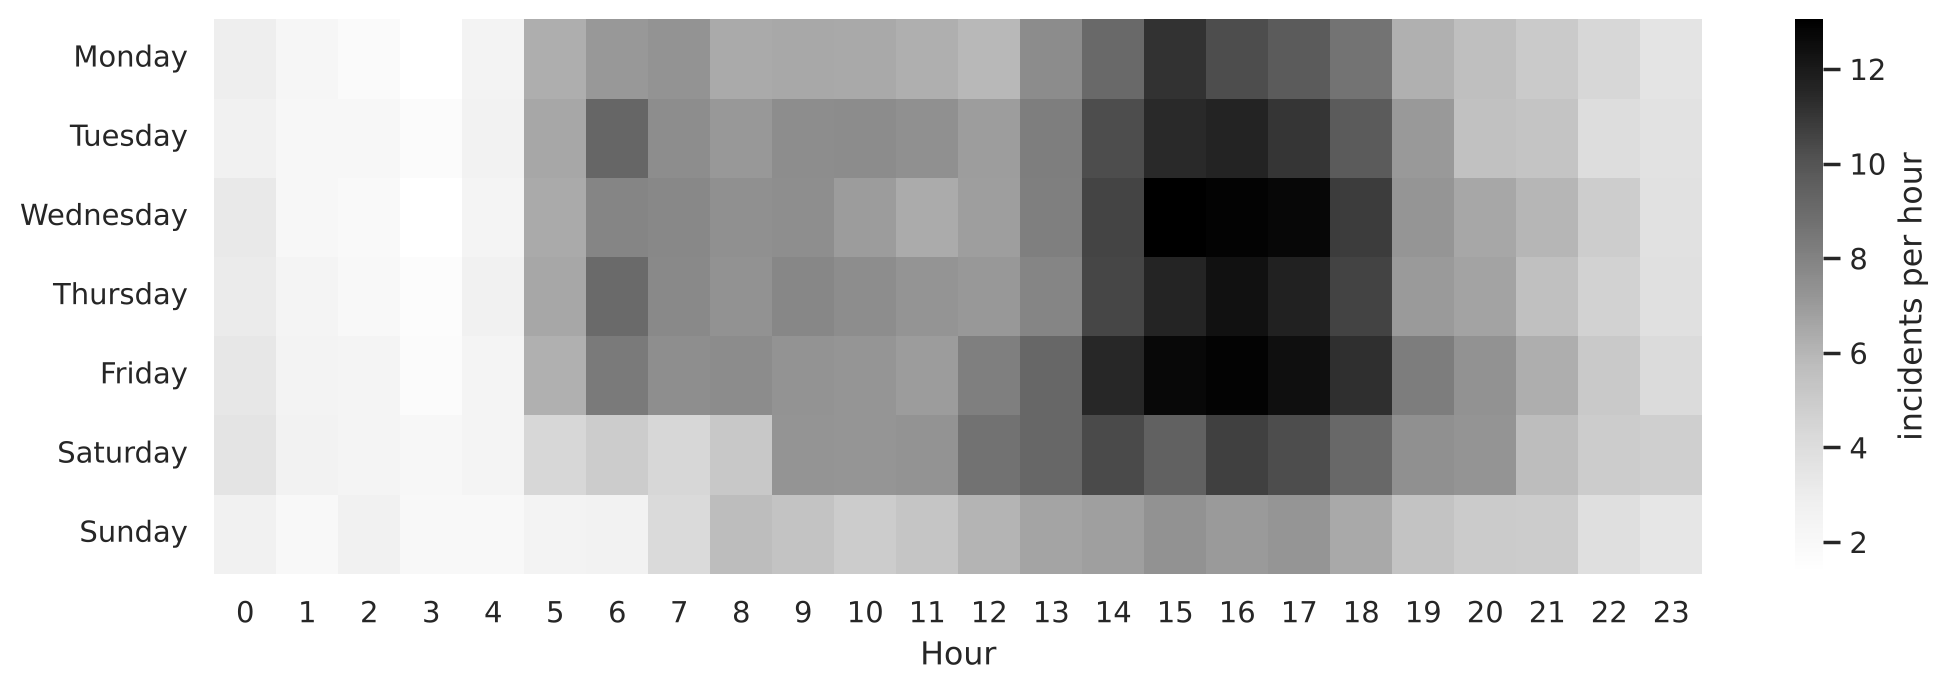

In [4]:
table = analysis.hour_weekday_table(hourly).reindex(DAY_ORDER)
fig, ax = plt.subplots(figsize=(12, 3.6))
sns.heatmap(table, cmap="Greys", ax=ax, cbar_kws={"label": "incidents per hour"})
ax.set(xlabel="Hour", ylabel="");

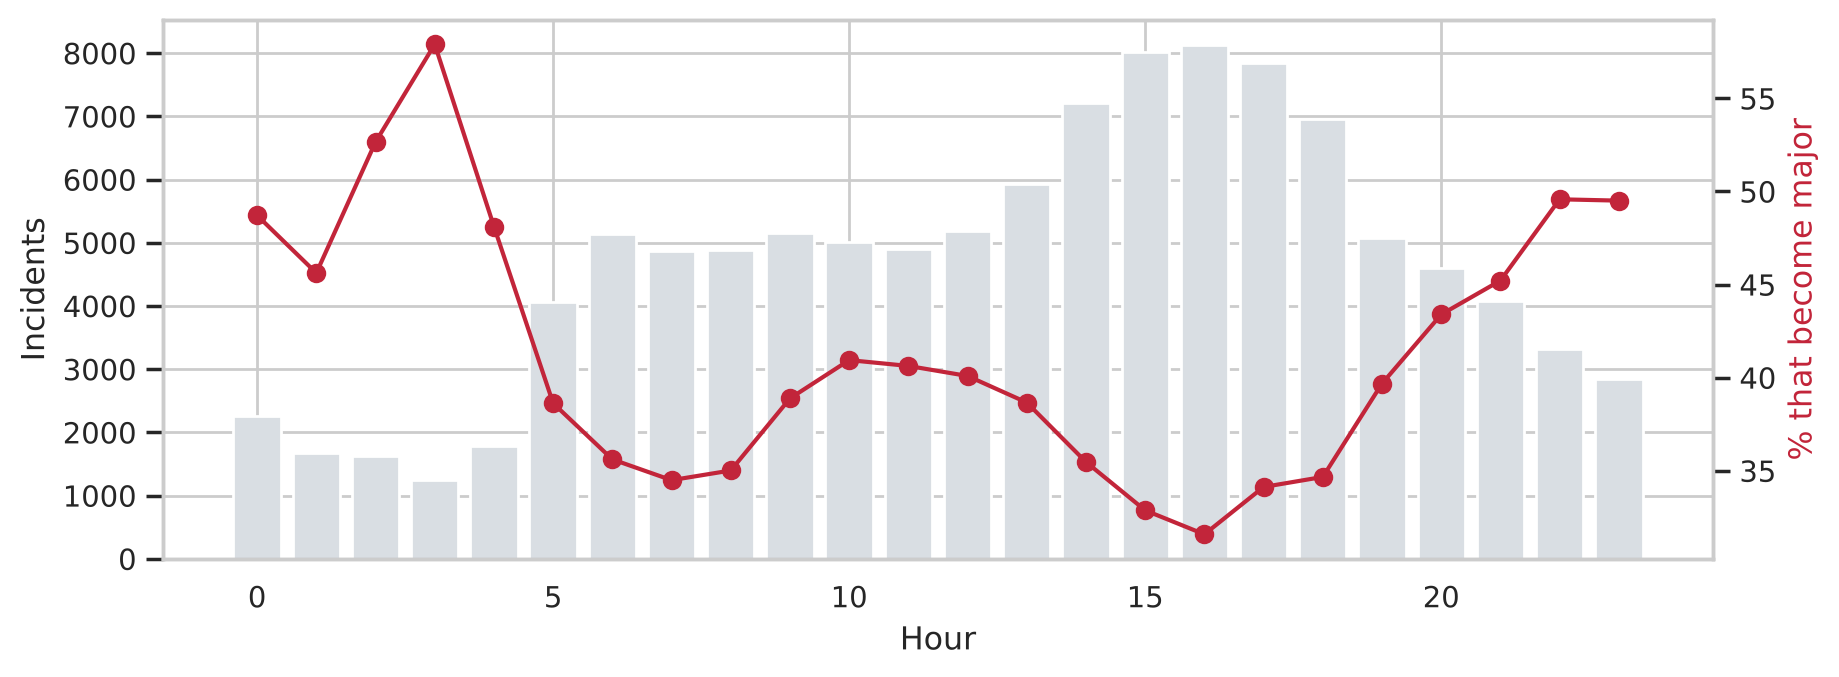

In [5]:
by_hour = inc.groupby("hour").agg(incidents=("delay_min", "size"), major_share=("major_delay", "mean"))
fig, ax1 = plt.subplots(figsize=(10, 3.5))
ax1.bar(by_hour.index, by_hour["incidents"], color="#D9DEE3"); ax1.set(xlabel="Hour", ylabel="Incidents")
ax2 = ax1.twinx(); ax2.plot(by_hour.index, by_hour["major_share"] * 100, color="#C2253A", marker="o")
ax2.set_ylabel("% that become major", color="#C2253A"); ax2.grid(False);

Rush hours have the most incidents. Late night has the worst ones: about half of incidents between midnight and 5 am become major delays, because night buses run less often, so one problem leaves a long gap.

## 4. Routes and causes

In [6]:
analysis.route_table(inc).head(10)

,route,incidents,median_delay,major_share
0,32,3632,12.0,0.240363
1,36,3155,6.0,0.094770
2,52,3041,18.0,0.656363
3,29,2631,8.0,0.114025
4,35,2591,10.0,0.107680
5,7,2174,10.0,0.070377
6,63,2105,10.0,0.085986
7,102,1899,10.0,0.418115
8,54,1887,13.0,0.311606
9,95,1806,10.0,0.203765


In [7]:
analysis.incident_table(inc)

,incident,incidents,median_delay,major_share
0,Mechanical,38791,11.0,0.355108
1,Operations - Operator,21152,12.0,0.407810
2,Security,9554,10.0,0.332845
3,Collision - TTC,7930,10.0,0.309836
4,General Delay,7146,9.0,0.395046
5,Emergency Services,6266,10.0,0.327960
6,Diversion,6086,35.0,0.769800
7,Utilized Off Route,4851,10.0,0.320552
8,Cleaning - Unsanitary,4481,12.0,0.430261
9,Vision,2687,12.0,0.397097


Diversions are by far the longest incidents (median 35 minutes even after capping delays at 120 minutes; 77% become major delays). Mechanical problems are the most common cause.

## 5. Does the weather matter?
A snowy hour should be compared with a normal hour at the same time of the week, not with the overall average (snow at 8 am Monday vs a dry 8 am Monday). `analysis.compare_to_expected` computes, for each group of hours, *actual incidents / expected incidents*, where expected is the average for that year, weekday and hour. The 90% range comes from bootstrapping (resampling the hours).

In [8]:
binned = analysis.snow_and_rain_bins(hourly)
snow = analysis.compare_to_expected(binned, "snowfall"); rain = analysis.compare_to_expected(binned, "rainfall")
pd.concat([snow.rename(columns={"snowfall": "group"}), rain.rename(columns={"rainfall": "group"})]).round(2)

,group,hours,incidents_per_hour,expected_per_hour,ratio,ratio_low,ratio_high
0,None,16986,6.33,6.36,1.00,0.99,1.00
1,Light (<0.5 cm/h),483,6.77,6.51,1.04,1.00,1.08
2,Moderate (0.5-1.5),55,10.64,6.84,1.55,1.34,1.76
3,Heavy (>1.5),20,15.40,7.16,2.15,1.57,2.63
0,None,15249,6.24,6.31,0.99,0.98,1.00
1,Light (<1 mm/h),1850,7.13,6.88,1.04,1.02,1.05
2,Moderate (1-4),383,7.79,6.44,1.21,1.16,1.25
3,Heavy (>4),62,7.32,6.30,1.16,1.06,1.27


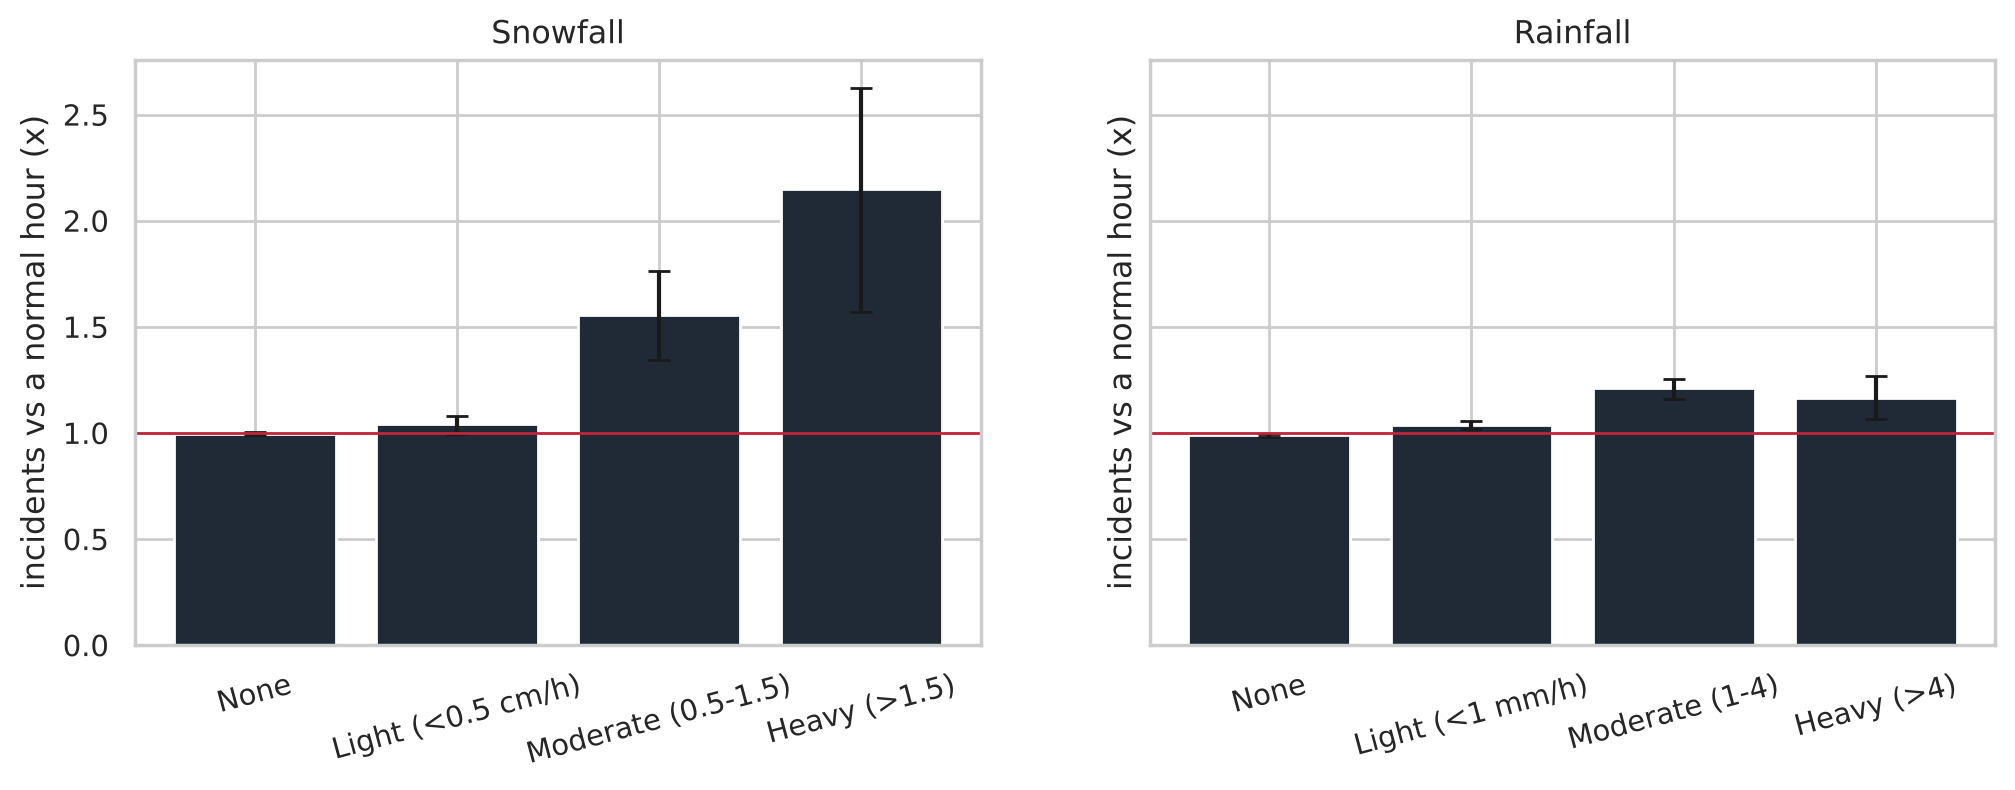

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, t, col in [(axes[0], snow, "snowfall"), (axes[1], rain, "rainfall")]:
    ax.bar(t[col].astype(str), t["ratio"], color="#1F2A36",
           yerr=[t["ratio"] - t["ratio_low"], t["ratio_high"] - t["ratio"]], capsize=4)
    ax.axhline(1, color="#C2253A", lw=1); ax.set(title=col.title(), ylabel="incidents vs a normal hour (x)")
    ax.tick_params(axis="x", rotation=15)

heavy snowfall (more than 1.5 cm per hour) went with about 2.2x the normal number of incidents, moderate snow about 1.5x, and moderate rain about 1.2x. Light rain and light snow made little difference. The heavy-snow estimate rests on only 20 hours, so its range is wide.

## 6. Events and holidays

In [10]:
games = analysis.compare_to_expected(hourly, "jays_game_window")
hols = analysis.compare_to_expected(hourly, "is_holiday")
pd.concat([games.assign(group="Blue Jays game window").rename(columns={"jays_game_window": "value"}),
           hols.assign(group="Ontario holiday").rename(columns={"is_holiday": "value"})]).round(2)

,value,hours,incidents_per_hour,expected_per_hour,ratio,ratio_low,ratio_high,group
0,0,16734,6.34,6.34,1.00,0.99,1.01,Blue Jays game window
1,1,810,7.00,6.92,1.01,0.99,1.04,Blue Jays game window
0,0,17088,6.44,6.37,1.01,1.00,1.02,Ontario holiday
1,1,456,3.70,6.18,0.60,0.57,0.63,Ontario holiday


Blue Jays home games (1 hour before to 4 hours after the first pitch) made no measurable difference (ratio about 1.01). Holidays have about 40% fewer incidents, because less service runs. A limitation: we only had a clean, free source for baseball games, so concerts, Raptors/Leafs games and festivals are not included.

## 7. Does weather change how long a delay lasts?
The model section answers this with an ablation: the delay model was retrained without any weather inputs and its 2024 error did not change. Weather changes how many incidents happen, not how long each one takes to clear.

In [11]:
import json
from config import METRICS_FILE
m = json.loads(METRICS_FILE.read_text())
pd.DataFrame(m["ablation"]).T.assign(note="retrained without this group")

,roc_auc,mae,note
weather inputs,0.8419,6.2948,retrained without this group
event inputs,0.8389,6.2923,retrained without this group
route,0.6021,7.6428,retrained without this group
incident type,0.8255,6.4268,retrained without this group


## Summary
- Data: 111,750 TTC bus delay incidents in 2023-24, joined with hourly Toronto weather, Blue Jays home games and Ontario holidays.
- Time: rush hours have the most incidents, late nights the worst ones.
- Route: the single strongest predictor of delay length (less frequent routes = longer gaps).
- Weather: heavy snow roughly doubles the number of incidents per hour, but does not make each incident longer.
- Events: no measurable effect from Blue Jays games; holidays are quieter.